# 02 · Feature engineering without label leakage

`FeatureState` streams the log in time order. For each transfer it **first computes** features from
what it has already seen and **only then** adds the transfer to history. So every feature uses
strictly earlier data, and the live risk service runs the exact same code one transfer at a time.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kronos_ml.config import load_config, DATA_DIR, MODELS_DIR, REPORT_DIR
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
cfg = load_config()

In [2]:
from kronos_ml.features.build import FEATURES, FEATURE_GROUPS
df = pd.read_parquet(DATA_DIR / "features.parquet")
pd.DataFrame([(g, ", ".join(f)) for g, f in FEATURE_GROUPS.items()], columns=["group", "features"])

,group,features
0,Amount,"amount_log, amount_z, amount_to_median, amount..."
1,Velocity,"tx_10m, tx_1h, tx_24h, amount_1h_log, secs_sin..."
2,Counterparty,"new_receiver, distinct_receivers_1h, receiver_..."
3,Graph / cycle,"round_trip_30m, cycle_3hop_60m, passthrough_ratio"
4,Time,"hour_sin, hour_cos, hour_rarity, is_weekend"
5,Account,"sender_age_days_log, sender_tx_count_log, warmup"
6,Physics,"distance_log, flight_time_s, bh_risk"


In [3]:
df[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(3)

,mean,std,min,50%,max
amount_log,3.031,0.998,0.293,3.138,8.294
amount_z,-0.160,1.186,-11.302,-0.081,10.489
amount_to_median,-0.175,0.971,-4.795,-0.049,4.190
amount_to_max,-1.689,1.418,-7.852,-1.291,3.768
amount_to_balance,0.140,0.211,0.000,0.028,1.000
tx_10m,0.125,1.540,0.000,0.000,55.000
tx_1h,0.317,1.627,0.000,0.000,55.000
tx_24h,2.108,2.512,0.000,2.000,55.000
amount_1h_log,0.607,1.339,0.000,0.000,7.228
secs_since_last_log,10.007,2.093,0.000,10.307,14.768


### How each pattern looks in feature space (median, standardised against normal traffic)

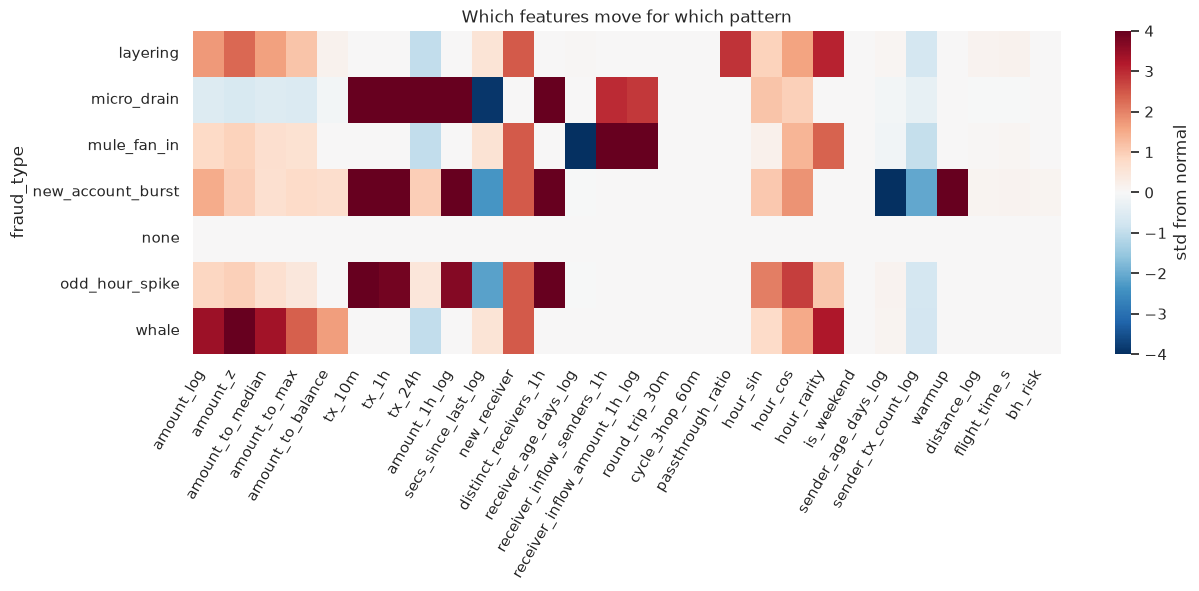

In [4]:
normal = df[df.is_fraud == 0][FEATURES]
z = (df.groupby("fraud_type")[FEATURES].median() - normal.median()) / normal.std().replace(0, 1)
plt.figure(figsize=(14, 4.2))
sns.heatmap(z.clip(-4, 4), cmap="RdBu_r", center=0, cbar_kws={"label": "std from normal"})
plt.title("Which features move for which pattern"); plt.xticks(rotation=60, ha="right");

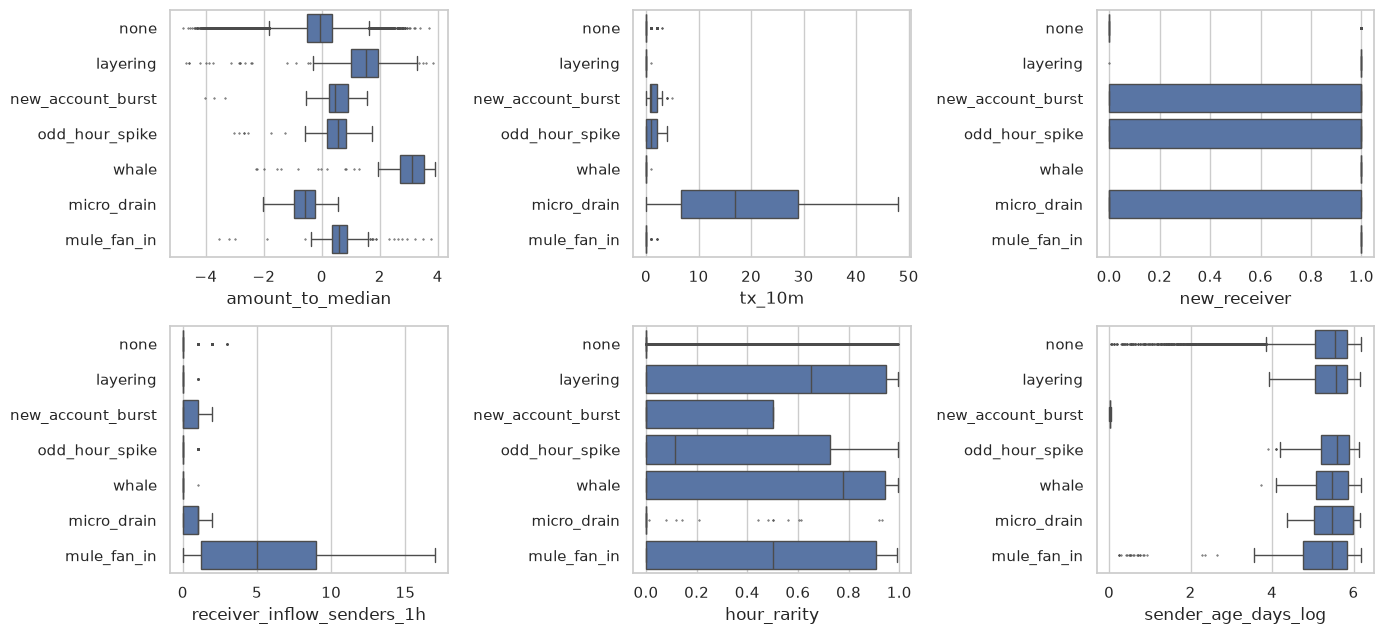

In [5]:
key = ["amount_to_median", "tx_10m", "new_receiver", "receiver_inflow_senders_1h", "hour_rarity", "sender_age_days_log"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, f in zip(axes.flat, key):
    sns.boxplot(data=df.sample(40000, random_state=0) if len(df) > 40000 else df, x=f, y="fraud_type", ax=ax, fliersize=0.5)
    ax.set_ylabel("")
plt.tight_layout()

### Proving there is no leakage

In [6]:
from kronos_ml.features.build import build_features
tx = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["created_at"]).iloc[:20000]
users = pd.read_csv(DATA_DIR / "users.csv", parse_dates=["created_at"])
full = build_features(tx, users)
cut = 10000
future = tx.iloc[cut:].copy()
rng = np.random.default_rng(0)
for c in ["sender_id", "receiver_id", "amount", "is_fraud"]:
    future[c] = rng.permutation(future[c].to_numpy())
scrambled = build_features(pd.concat([tx.iloc[:cut], future]), users)
diff = (full.iloc[:cut] - scrambled.iloc[:cut]).abs().to_numpy().max()
print(f"max change in the first {cut:,} rows after scrambling the future: {diff}")
assert diff == 0

max change in the first 10,000 rows after scrambling the future: 0.0


The same property is enforced by `ml/tests/test_no_leakage.py`, and `test_features.py` checks that one-at-a-time (online) features equal the batch features.

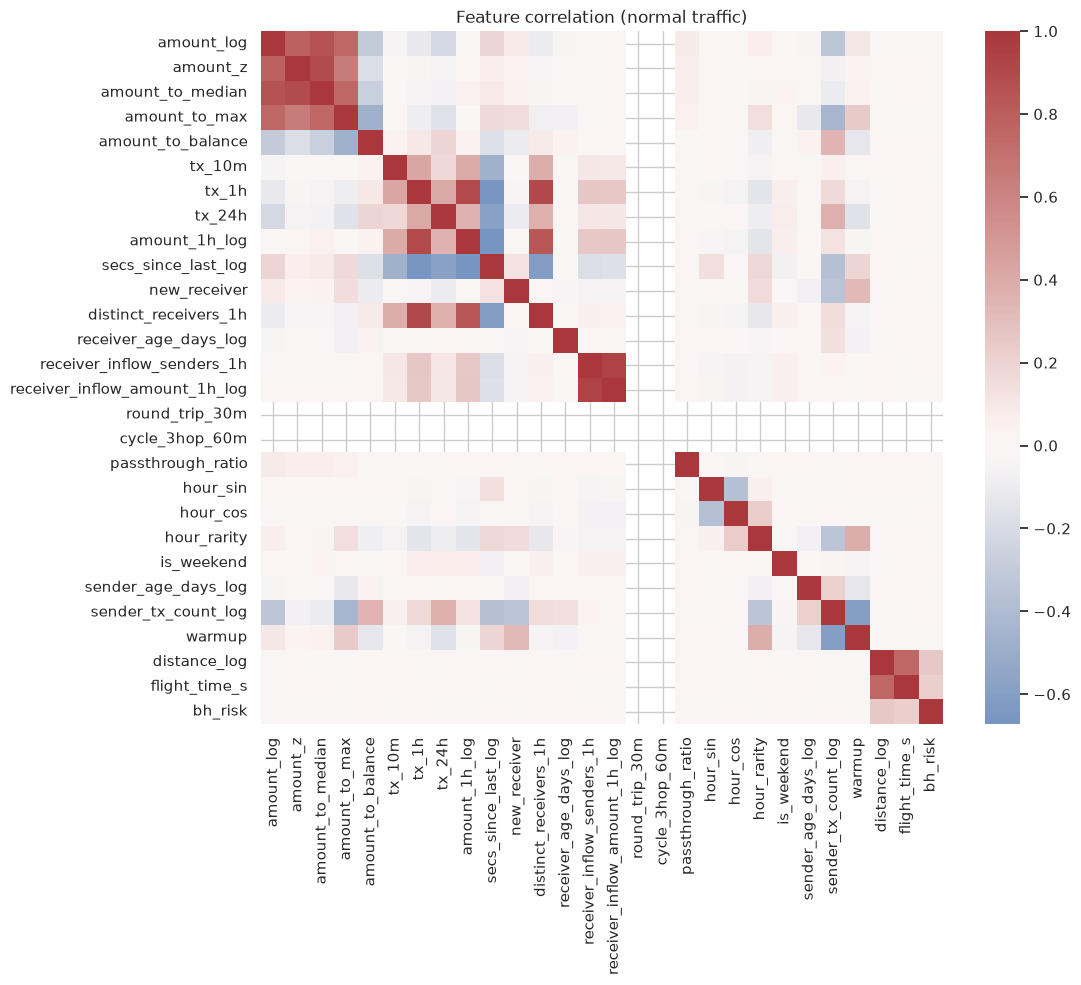

In [7]:
plt.figure(figsize=(11, 9))
sns.heatmap(normal.sample(20000, random_state=0).corr(), cmap="vlag", center=0)
plt.title("Feature correlation (normal traffic)");